In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
file_path = '../data/processed/inc5000_2014_clean.csv'

df = pd.read_csv(file_path)

df_clean = df.copy()

df_clean.shape

(5000, 13)


Cantidad de empresas -¿Qué industrias tienen mayor representación?
Ingresos	         -¿Qué industrias generan mayores ingresos?
Crecimiento	         -¿Qué industrias presentan mayores tasas de crecimiento?
Empleo	             -¿Qué industrias concentran más trabajadores?
Comparación	         -¿Cómo se comportan las industrias al comparar ingresos, crecimiento y empleo?

In [39]:
#Cantidad de empresas -¿Qué industrias tienen mayor representación?
most_rep_ind = (df_clean.groupby('industry', as_index=False)['company']
                  .agg(['count'])
                  .sort_values(['count'], ascending=False))

most_rep_ind

,industry,count
14,IT Services,733
0,Advertising & Marketing,453
1,Business Products & Services,435
12,Health,377
22,Software,338
9,Financial Services,278
4,Consumer Products & Services,230
11,Government Services,212
17,Manufacturing,212
20,Retail,200


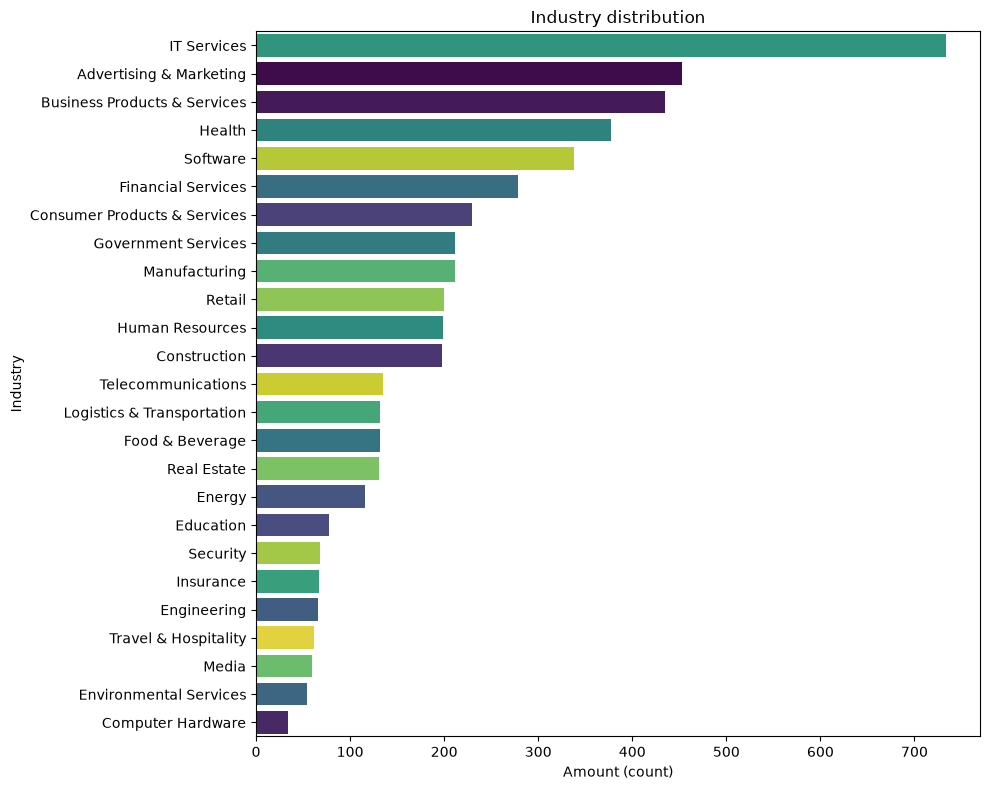

In [42]:
#grafico 
plt.figure(figsize=(10, 8))

sns.barplot(
    x=most_rep_ind['count'], y=most_rep_ind['industry'], 
    palette='viridis', hue=most_rep_ind.index, legend=False
)

plt.title('Industry distribution')
plt.xlabel('Amount (count)')
plt.ylabel('Industry')

plt.tight_layout()
plt.show()


La industria de IT Services presenta la mayor representación dentro de la clasificación, con 733 empresas, lo que corresponde al 14,66 % del total. Le siguen Advertising & Marketing, con 453 empresas, y Business Products & Services, con 435. Esto demuestra que IT Services fue el sector con mayor presencia entre las empresas incluidas en esta edición del ranking.

In [70]:
#Ingresos -¿Qué industrias generan mayores ingresos?
most_revenue = (
    df_clean.groupby('industry', as_index=False)['revenue']
    .sum().sort_values('revenue', ascending=False)
)

most_revenue

,industry,revenue
12,Health,22022876049
6,Energy,21602659306
14,IT Services,19363587015
1,Business Products & Services,17175083779
9,Financial Services,12212242543
13,Human Resources,12174441948
16,Logistics & Transportation,11208388344
4,Consumer Products & Services,10746810431
3,Construction,10342377737
23,Telecommunications,9336973728


La industria Health registra los mayores ingresos acumulados dentro de la clasificación Inc. 5000 de 2014, con aproximadamente $22.02 mil millones. Le siguen Energy e IT Services. Este resultado demuestra que la industria con mayor representación en cantidad de empresas no necesariamente es la que concentra los mayores ingresos totales.

In [66]:
most_revenue['mean'] = most_revenue['revenue'] / most_rep_ind['count']

all_together = pd.merge(most_rep_ind, most_revenue, on='industry').sort_values('mean', ascending=False)

all_together

,industry,count,revenue,mean
16,Energy,116,21602659306,1.862298e+08
13,Logistics & Transportation,132,11208388344,8.491203e+07
12,Telecommunications,135,9336973728,6.916277e+07
19,Insurance,67,4550304954,6.791500e+07
15,Real Estate,131,8886571850,6.783643e+07
10,Human Resources,199,12174441948,6.117810e+07
21,Travel & Hospitality,62,3644726185,5.878591e+07
3,Health,377,22022876049,5.841612e+07
11,Construction,198,10342377737,5.223423e+07
14,Food & Beverage,132,6481046076,4.909883e+07


In [90]:
revenue_comparison = (
    df_clean.groupby('industry', as_index=False)['revenue']
    .agg(['count', 'mean', 'median'])
    .sort_values('mean', ascending=False)
)

most_revenue_final = pd.merge(revenue_comparison, most_revenue, on='industry')

most_revenue_final

,industry,count,mean,median,revenue
0,Energy,116,1.862298e+08,27894920.0,21602659306
1,Logistics & Transportation,132,8.491203e+07,20529535.5,11208388344
2,Telecommunications,135,6.916277e+07,17283580.0,9336973728
3,Insurance,67,6.791500e+07,17010859.0,4550304954
4,Real Estate,131,6.783643e+07,10483829.0,8886571850
5,Human Resources,199,6.117810e+07,13657622.0,12174441948
6,Travel & Hospitality,62,5.878591e+07,12304765.5,3644726185
7,Health,377,5.841612e+07,13821000.0,22022876049
8,Construction,198,5.223423e+07,12068630.0,10342377737
9,Food & Beverage,132,4.909883e+07,16296868.5,6481046076


La industria Energy presenta los mayores ingresos promedio por empresa, con aproximadamente $186.23 millones. Sin embargo, al comparar este resultado con su mediana de $27.89 millones, se observa una diferencia considerable, lo que sugiere la presencia de empresas con ingresos excepcionalmente elevados. Por otra parte, industrias como Health y Telecommunications también presentan diferencias importantes entre ambos indicadores. Esto demuestra la importancia de utilizar tanto el promedio como la mediana para comprender mejor la distribución de los ingresos.

In [75]:
energy_companies = (
    df_clean[df_clean['industry'] == 'Energy']
    .nlargest(5, 'revenue')
    [['company', 'revenue', 'growth', 'workers']]
)

energy_companies

,company,revenue,growth,workers
3690,Eco-Energy Global Biofuels,4138790000,86.5446,109.0
256,Bridger,3487872233,1792.1589,105.0
4203,Flyers Energy,1977921907,67.9592,450.0
3425,Sun Coast Resources,1868964476,97.3349,1668.0
2073,Ambit Energy,1211399000,193.6155,625.0


In [87]:
#Crecimiento-¿Qué industrias presentan mayores tasas de crecimiento?
most_growth = (
    df_clean.groupby('industry', as_index=False)['growth']
    .agg(['count','mean','median']).sort_values('mean', ascending=False)
)

sum_growth = df_clean.groupby('industry')['growth'].sum()

most_growth = pd.merge(most_growth, sum_growth, on='industry')

most_growth

,industry,count,mean,median,growth
0,Consumer Products & Services,230,1331.791067,198.63470,306311.9455
1,Energy,116,970.035263,193.12880,112524.0905
2,Food & Beverage,132,963.141847,176.53955,127134.7238
3,Health,377,637.632964,169.34860,240387.6274
4,Government Services,212,594.710256,218.95655,126078.5743
5,Real Estate,131,576.903832,198.73960,75574.4020
6,Financial Services,278,572.454370,159.22720,159142.3149
7,Software,338,557.109204,207.76595,188302.9110
8,Travel & Hospitality,62,547.304384,120.99940,33932.8718
9,Retail,200,529.522372,215.37335,105904.4744


La industria Consumer Products & Services presenta el mayor crecimiento promedio, con un 1,331.79 %, seguida de Energy y Food & Beverage. Sin embargo, al comparar los promedios con las medianas, se observan diferencias considerables que sugieren la influencia de empresas con crecimientos excepcionalmente elevados. Por otra parte, Government Services presenta una mediana superior a la de algunas industrias con mayores promedios, lo que evidencia la importancia de utilizar ambos indicadores para comprender el comportamiento del crecimiento empresarial.

In [89]:
#Empleo-¿Qué industrias concentran más trabajadores?
most_workers = (
    df_clean.groupby('industry', as_index=False)['workers']
    .agg(['count','mean','median']).sort_values('count' \
    '', ascending=False)
)

sum_workers = df_clean.groupby('industry')['workers'].sum()

most_workers = pd.merge(most_workers, sum_workers, on='industry')

most_workers

,industry,count,mean,median,workers
0,IT Services,732,152.543716,60.0,111662.0
1,Advertising & Marketing,453,61.114790,36.0,27685.0
2,Business Products & Services,433,269.314088,44.0,116613.0
3,Health,375,246.632000,80.0,92487.0
4,Software,337,133.059347,58.0,44841.0
5,Financial Services,278,153.694245,47.0,42727.0
6,Consumer Products & Services,230,106.047826,35.0,24391.0
7,Government Services,212,133.386792,68.0,28278.0
8,Manufacturing,210,160.842857,50.0,33777.0
9,Retail,199,169.507538,27.0,33732.0


In [94]:
#ingresos promedio por trabajador según industria.
revenue_workers = (
    df_clean.dropna(subset=['workers'])
    .groupby('industry', as_index=False)
    .agg(
        total_revenue=('revenue', 'sum'),
        total_workers=('workers', 'sum')
    )
)

revenue_workers['revenue_per_worker'] = (
    revenue_workers['total_revenue'] /
    revenue_workers['total_workers']
)

revenue_workers = revenue_workers.sort_values(
    'revenue_per_worker', ascending=False
)

revenue_workers

,industry,total_revenue,total_workers,revenue_per_worker
6,Energy,21602659306,23981.0,900823.956716
2,Computer Hardware,1149110342,1970.0,583304.742132
19,Real Estate,8797794356,19608.0,448683.922685
4,Consumer Products & Services,10746810431,24391.0,440605.568898
3,Construction,10342377737,23575.0,438701.070498
16,Logistics & Transportation,11208388344,29020.0,386229.784425
15,Insurance,4550304954,12698.0,358348.161443
9,Financial Services,12212242543,42727.0,285820.266880
0,Advertising & Marketing,7317073720,27685.0,264297.407260
20,Retail,8355294290,33732.0,247696.379995


Energy destaca considerablemente. Tiene aproximadamente $21.6 mil millones en ingresos y 23,981 trabajadores. Su relación entre ingresos y trabajadores es muy superior a la de las demás industrias.

Computer Hardware ocupa el segundo lugar, aunque tiene solamente 34 empresas en el conjunto de datos. Es un buen ejemplo de por qué conviene analizar tanto la cantidad de empresas como sus resultados económicos.

Human Resources y Security presentan valores bajos. Esto podría estar relacionado con la naturaleza de sus actividades y la cantidad de personal que requieren, aunque estos datos por sí solos no permiten demostrar la causa.